# Amazon Satış Verileri Analizi (EDA)
Bu projede, Amazon'daki ürünlerin fiyatlandırma stratejilerini, indirim oranlarını ve müşteri puanları arasındaki ilişkileri analiz ediyoruz.

### Veri Seti İçeriği:
* **actual_price:** Ürünün orijinal fiyatı
* **discounted_price:** İndirimli satış fiyatı
* **rating:** Müşteri puanı
* **category:** Ürün kategorisi

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Veri Kontrolleri Yapıyoruz

In [3]:
df_amazon = pd.read_csv("amazon.csv")

In [4]:
df_amazon.shape

(1465, 16)

In [5]:
df_amazon

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1460,B08L7J3T31,Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...,Home&Kitchen|Kitchen&HomeAppliances|WaterPurif...,₹379,₹919,59%,4,"1,090",SUPREME QUALITY 90 GRAM 3 LAYER THIK PP SPUN F...,"AHITFY6AHALOFOHOZEOC6XBP4FEA,AFRABBODZJZQB6Z4U...","Prabha ds,Raghuram bk,Real Deal,Amazon Custome...","R3G3XFHPBFF0E8,R3C0BZCD32EIGW,R2EBVBCN9QPD9R,R...","Received the product without spanner,Excellent...","I received product without spanner,Excellent p...",https://m.media-amazon.com/images/I/41fDdRtjfx...,https://www.amazon.in/Noir-Aqua-Spanner-Purifi...
1461,B01M6453MB,Prestige Delight PRWO Electric Rice Cooker (1 ...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,"₹2,280","₹3,045",25%,4.1,"4,118","230 Volts, 400 watts, 1 Year","AFG5FM3NEMOL6BNFRV2NK5FNJCHQ,AGEINTRN6Z563RMLH...","Manu Bhai,Naveenpittu,Evatira Sangma,JAGANNADH...","R3DDL2UPKQ2CK9,R2SYYU1OATVIU5,R1VM993161IYRW,R...","ok,everything was good couldn't return bcoz I ...","ok,got everything as mentioned but the me

In [6]:
df_amazon.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-null   object
dtypes: obj

## Burada bizim için gereksiz gördüğümüz verileri siliyoruz

In [7]:
columns_to_drop = ["about_product", "review_title", "review_content", "img_link", "product_link" ]
df_amazon = df_amazon.drop(columns=[col for col in columns_to_drop if col in df_amazon.columns])

In [8]:
df_amazon

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,user_id,user_name,review_id
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269","AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K..."
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY..."
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928","AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2..."
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363","AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1..."
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905","AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R..."
...,...,...,...,...,...,...,...,...,...,...,...
1460,B08L7J3T31,Noir Aqua - 5pcs PP Spun Filter + 1 Spanner | ...,Home&Kitchen|Kitchen&HomeAppliances|WaterPurif...,₹379,₹919,59%,4,"1,090","AHITFY6AHALOFOHOZEOC6XBP4FEA,AFRABBODZJZQB6Z4U...","Prabha ds,Raghuram bk,Real Deal,Amazon Custome...","R3G3XFHPBFF0E8,R3C0BZCD32EIGW,R2EBVBCN9QPD9R,R..."
1461,B01M6453MB,Prestige Delight PRWO Electric Rice Cooker (1 ...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,"₹2,280","₹3,045",25%,4.1,"4,118","AFG5FM3NEMOL6BNFRV2NK5FNJCHQ,AGEINTRN6Z563RMLH...","Manu Bhai,Naveenpittu,Evatira Sangma,JAGANNADH...","R3DDL2UPKQ2CK9,R2SYYU1OATVIU5,R1VM993161IYRW,R..."
1462,B009P2LIL4,Bajaj Majesty RX10 2000 Watts Heat Convector R...,"Home&Kitchen|Heating,Cooling&AirQuality|RoomHe...","₹2,219","₹3,080",28%,3.6,468,"AGVPWCMAHYQWJOQKMUJN4DW3KM5Q,AF4Q3E66MY4SR7YQZ...","Nehal Desai,Danish Parwez,Amazon Customer,Amaz...","R1TLRJVW4STY5I,R2O455KRN493R1,R3Q5MVGBRIAS2G,R..."
1463,B00J5DYCCA,Havells Ventil Air DSP 230mm Exhaust Fan (Pist...,"Home&Kitchen|Heating,Cooling&AirQuality|Fans|E...","₹1,399","₹1,890",26%,4,"8,031","AF2JQCLSCY3QJATWUNNHUSVUPNQQ,AFDMLUXC5LS5RXDJS...","Shubham Dubey,E.GURUBARAN,Mayank S.,eusuf khan...","R39Q2Y79MM9SWK,R3079BG1NIH6MB,R29A31ZELTZNJM,R..."


In [9]:
df_amazon.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   user_id              1465 non-null   object
 9   user_name            1465 non-null   object
 10  review_id            1465 non-null   object
dtypes: object(11)
memory usage: 126.0+ KB


In [10]:
df_amazon.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,user_id,user_name,review_id
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269","AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K..."
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY..."
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928","AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2..."
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363","AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1..."
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905","AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R..."


## Veri Temizleme ve Tip Dönüşümü
Veri setindeki fiyatlar ve indirim oranları metin (string) formatında olduğu için matematiksel analiz yapılamıyordu. 
Bu bölümde para birimi simgelerini (`₹`) ve özel karakterleri (`,`, `%`) temizleyerek veriyi `float` tipine dönüştürüyoruz.

In [11]:
df_amazon["discounted_price"] =df_amazon["discounted_price"].str.replace("₹", "").str.replace("," , "").astype(float)

In [12]:
df_amazon["actual_price"] = df_amazon["actual_price"].str.replace("₹", "").str.replace(",", "").astype(float)

In [13]:
df_amazon[["discounted_price", "actual_price"]].describe()

,discounted_price,actual_price
count,1465.000000,1465.000000
mean,3125.310874,5444.990635
std,6944.304394,10874.826864
min,39.000000,39.000000
25%,325.000000,800.000000
50%,799.000000,1650.000000
75%,1999.000000,4295.000000
max,77990.000000,139900.000000


In [14]:
df_amazon.rating = pd.to_numeric(df_amazon["rating"], errors="coerce")

In [15]:
df_amazon.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1465 non-null   object 
 1   product_name         1465 non-null   object 
 2   category             1465 non-null   object 
 3   discounted_price     1465 non-null   float64
 4   actual_price         1465 non-null   float64
 5   discount_percentage  1465 non-null   object 
 6   rating               1464 non-null   float64
 7   rating_count         1463 non-null   object 
 8   user_id              1465 non-null   object 
 9   user_name            1465 non-null   object 
 10  review_id            1465 non-null   object 
dtypes: float64(3), object(8)
memory usage: 126.0+ KB


In [16]:
df_amazon.rating_count = df_amazon["rating_count"].str.replace(",", "").astype(float)

In [17]:
df_amazon[["rating","rating_count"]].isnull().sum()

rating          1
rating_count    2
dtype: int64

In [18]:
df_amazon.dropna(subset=["rating","rating_count"], inplace=True)

In [19]:
df_amazon["price_difference"] = df_amazon["actual_price"] - df_amazon["discounted_price"]

In [20]:
df_amazon.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,user_id,user_name,review_id,price_difference
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,399.0,1099.0,64%,4.2,24269.0,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...",700.0
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,199.0,349.0,43%,4.0,43994.0,"AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...",150.0
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,199.0,1899.0,90%,3.9,7928.0,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...",1700.0
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,329.0,699.0,53%,4.2,94363.0,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...",370.0
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,154.0,399.0,61%,4.2,16905.0,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...",245.0


In [21]:
df_amazon.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1462 entries, 0 to 1464
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1462 non-null   object 
 1   product_name         1462 non-null   object 
 2   category             1462 non-null   object 
 3   discounted_price     1462 non-null   float64
 4   actual_price         1462 non-null   float64
 5   discount_percentage  1462 non-null   object 
 6   rating               1462 non-null   float64
 7   rating_count         1462 non-null   float64
 8   user_id              1462 non-null   object 
 9   user_name            1462 non-null   object 
 10  review_id            1462 non-null   object 
 11  price_difference     1462 non-null   float64
dtypes: float64(5), object(7)
memory usage: 148.5+ KB


In [22]:
category_discount_Avg = df_amazon.groupby("category")["price_difference"].mean().sort_values(ascending=False)

In [23]:
top_5_popular_categories = df_amazon.groupby("category")["rating_count"].sum().sort_values(ascending=False).head(5)

In [24]:
df_amazon[["actual_price","rating"]].corr()

,actual_price,rating
actual_price,1.000000,0.122467
rating,0.122467,1.000000


In [25]:
df_amazon["category"].unique()
df_amazon["category"]= df_amazon["category"].str.split("|").str[0]

In [26]:
category_discount_Avg

category
Home&Kitchen|Heating,Cooling&AirQuality|AirConditioners|Split-SystemAirConditioners                                   33000.000000
Computers&Accessories|Laptops|TraditionalLaptops                                                                      22643.000000
Computers&Accessories|ExternalDevices&DataStorage|ExternalSolidStateDrives                                            21611.000000
Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cleaning&Ironing|Vacuums&FloorCare|Vacuums|RoboticVacuums                  21500.000000
Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions                                                         15292.650794
                                                                                                                          ...     
OfficeProducts|OfficePaperProducts|Paper|Stationery|Pens,Pencils&WritingSupplies|Pens&Refills|FountainPens                0.000000
OfficeProducts|OfficePaperProducts|Paper|Stationery|Pens,Pencils&WritingSu

In [27]:
category_discount_Avg = df_amazon.groupby("category")["price_difference"].mean().sort_values(ascending=False).head(10)

## Veri Görselleştirme
Kategorilere göre indirim stratejilerini inceliyoruz. Aşağıdaki grafik, Amazon'da en yüksek indirim oranına sahip olan ilk 10 kategoriyi göstermektedir.

/var/folders/n_/dfd008j95f371z7x751pd1200000gn/T/ipykernel_10710/1855964248.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_discount_avg.values, y=category_discount_avg.index, palette='viridis')


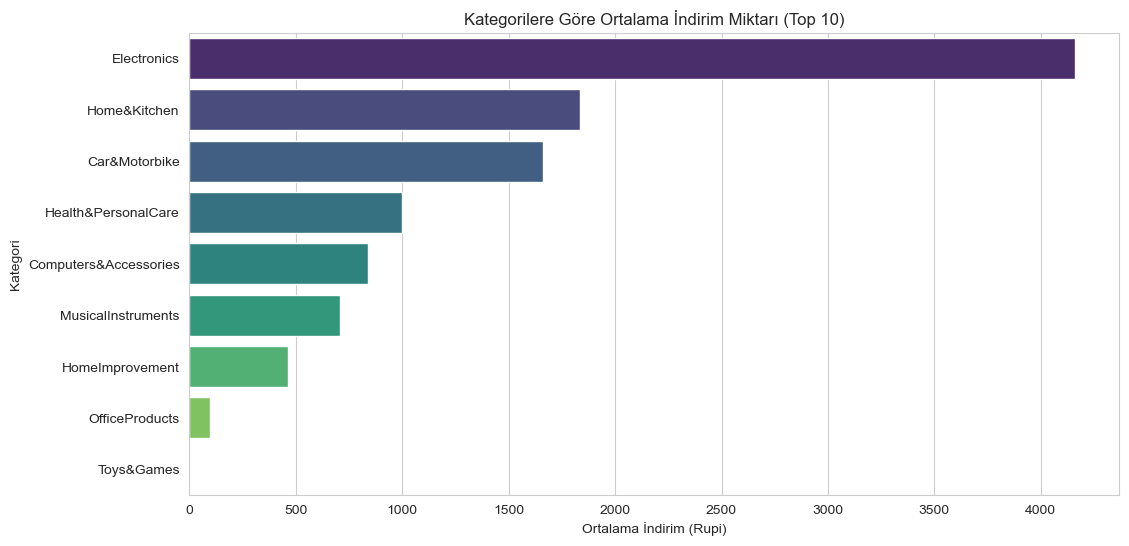

In [47]:
# 1. Tuval boyutunu ayarla
plt.figure(figsize=(12,6))

# 2. Veriyi hazırla ve çiz 
category_discount_avg = df_amazon.groupby('category')['price_difference'].mean().sort_values(ascending=False).head(10)
sns.barplot(x=category_discount_avg.values, y=category_discount_avg.index, palette='viridis')

# 3. Detayları ekledik
plt.title('Kategorilere Göre Ortalama İndirim Miktarı (Top 10)')
plt.xlabel('Ortalama İndirim (Rupi)')
plt.ylabel('Kategori')

#4. Kaydet
plt.savefig('grafik_adi.png')

# 5. Göster
plt.show()

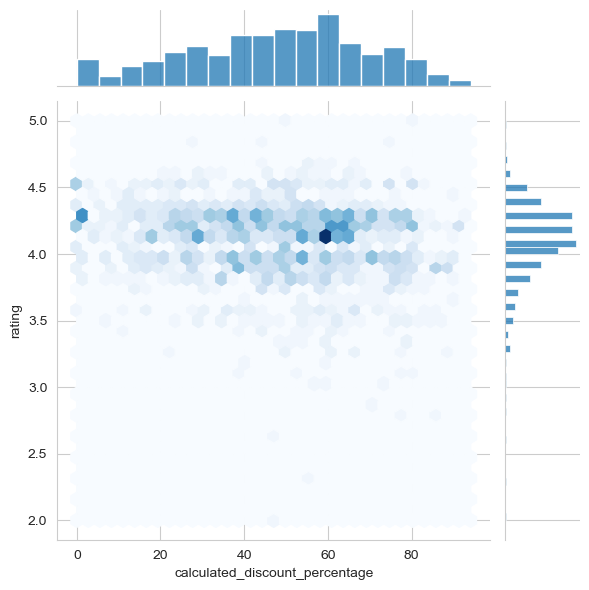

In [50]:
# 'kind="hex"' noktaları altıgen hücrelerde birleştirir ve yoğunluğu renkle gösterir
sns.jointplot(x='calculated_discount_percentage', y='rating', data=df_amazon, kind="hex", cmap='Blues')
plt.show()


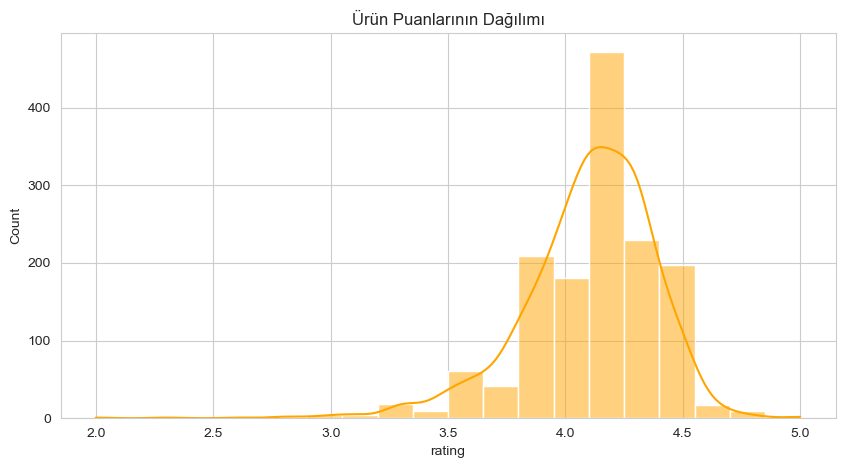

In [57]:
plt.figure(figsize=(10,5))

sns.histplot(df_amazon["rating"], bins=20, kde=True, color="orange")
plt.title("Ürün Puanlarının Dağılımı")
plt.savefig('amazon_Histogram.png', dpi=300, bbox_inches="tight")
plt.show()

In [30]:
df_amazon.head(5)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,user_id,user_name,review_id,price_difference
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories,399.0,1099.0,64%,4.2,24269.0,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...",700.0
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories,199.0,349.0,43%,4.0,43994.0,"AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...",150.0
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories,199.0,1899.0,90%,3.9,7928.0,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...",1700.0
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories,329.0,699.0,53%,4.2,94363.0,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...",370.0
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories,154.0,399.0,61%,4.2,16905.0,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...",245.0


## Özellik Mühendisliği (Feature Engineering)
Veri setindeki mevcut indirim oranlarına güvenmek yerine, `actual_price` ve `discounted_price` sütunlarını kullanarak **gerçek indirim oranlarını** kendimiz hesaplıyoruz.

In [31]:
df_amazon["discount_percentage"] = df_amazon["discount_percentage"].str.replace("%","").astype(float)


In [32]:
df_amazon["calculated_discount_percentage"] = (df_amazon["actual_price"] - df_amazon["discounted_price"]) / df_amazon["actual_price"] * 100

In [33]:
df_amazon[["discount_percentage","calculated_discount_percentage"]].head()

,discount_percentage,calculated_discount_percentage
0,64.0,63.694268
1,43.0,42.979943
2,90.0,89.520800
3,53.0,52.932761
4,61.0,61.403509


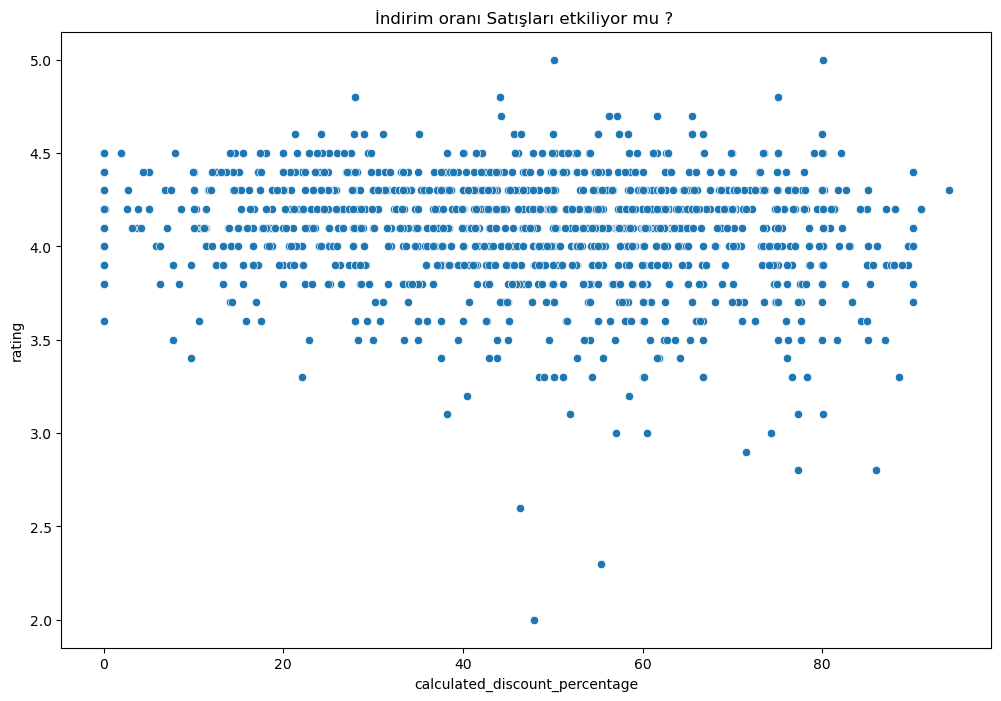

In [34]:
plt.figure(figsize=(12,8))

sns.scatterplot(x="calculated_discount_percentage", y="rating", data=df_amazon )
plt.title("İndirim oranı Satışları etkiliyor mu ? ")
plt.show()

In [35]:
top_5_cat_counts = df_amazon["category"].value_counts().head(5)

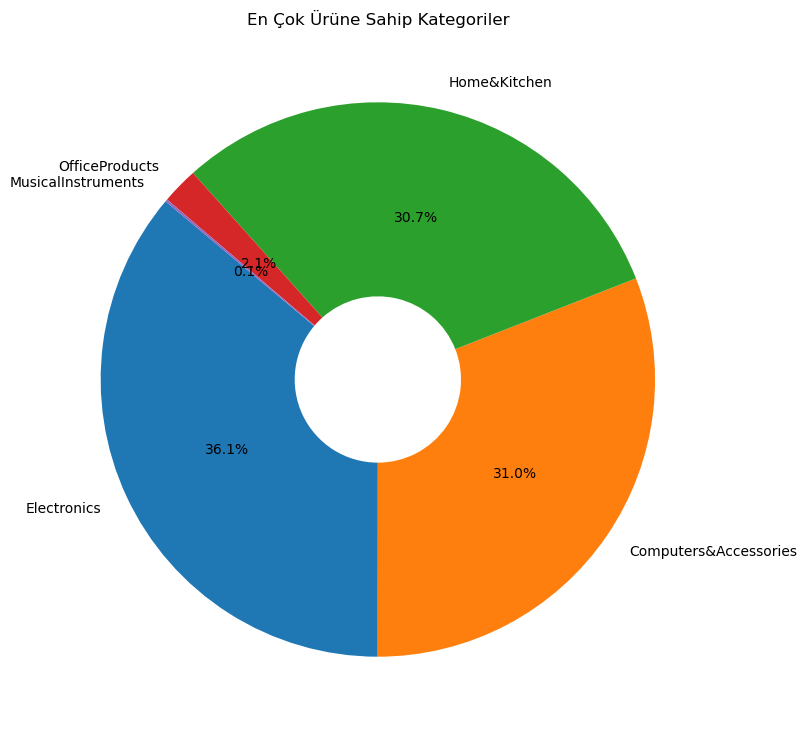

In [36]:
plt.figure(figsize=(15,9))
plt.pie(top_5_cat_counts, labels=top_5_cat_counts.index, autopct='%1.1f%%', startangle=140, wedgeprops={'width': 0.7})
plt.title("En Çok Ürüne Sahip Kategoriler")
plt.show()

In [37]:
df_top_5 = df_amazon[df_amazon["category"].isin(top_5_cat_counts.index)]

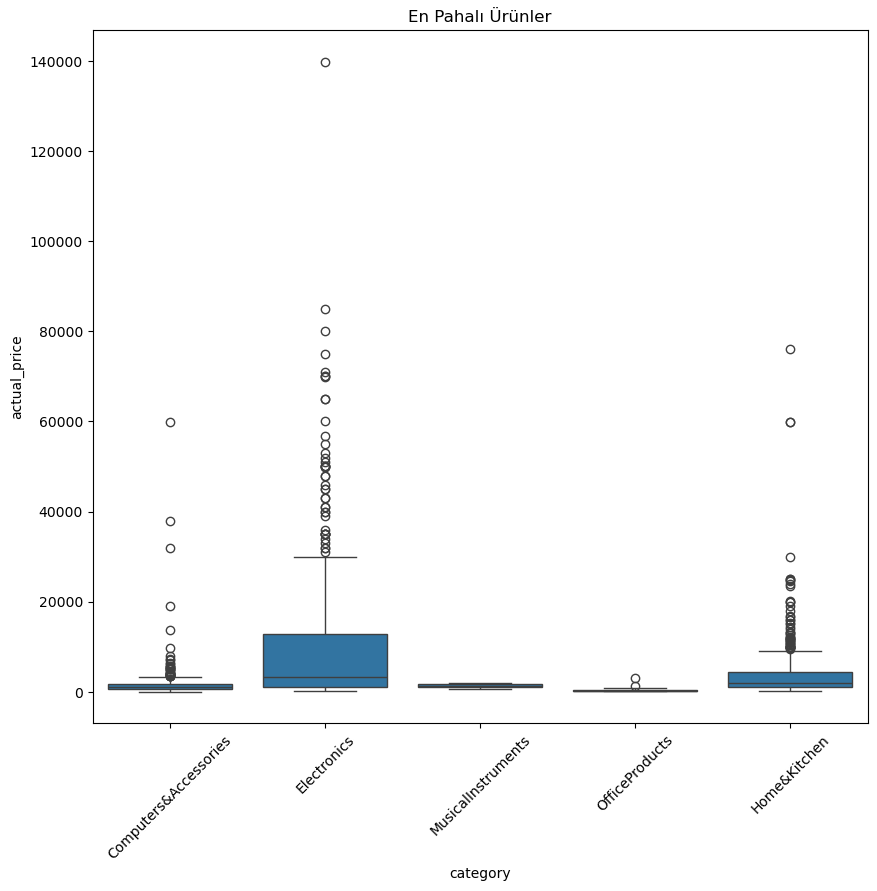

In [38]:
plt.figure(figsize=(10,9))
sns.boxplot(x="category", y="actual_price", data=df_top_5)
plt.xticks(rotation=45)
plt.title("En Pahalı Ürünler")
plt.show()

In [39]:
corr_matrix = df_amazon[["actual_price","discounted_price","rating","rating_count","calculated_discount_percentage"]].corr()

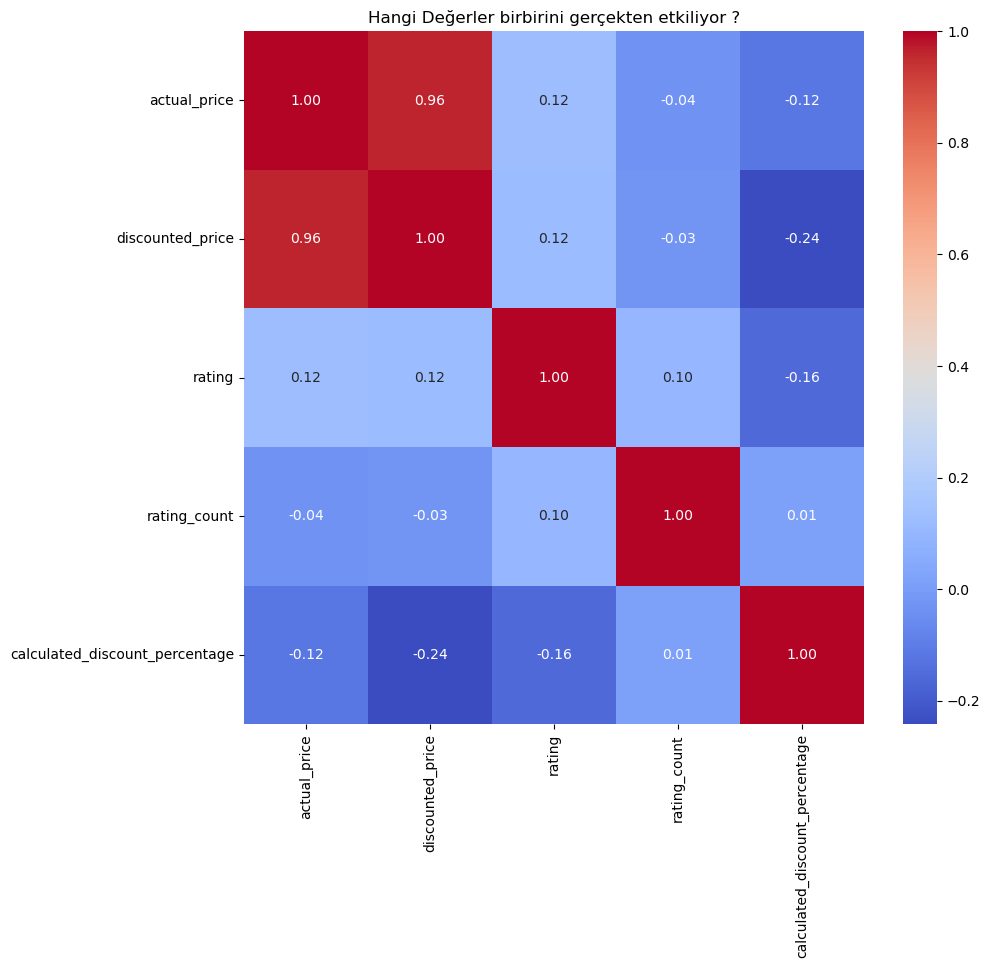

In [40]:
plt.figure(figsize=(10,9))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Hangi Değerler birbirini gerçekten etkiliyor ?")
plt.show()

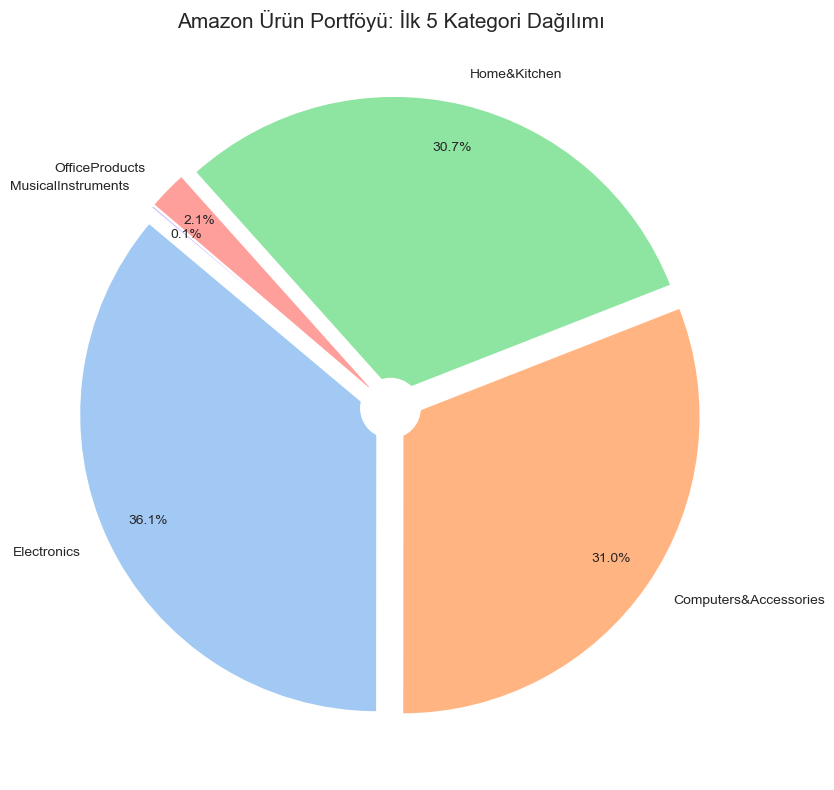

In [55]:
top_categories = df_amazon['category'].value_counts().head(5)
plt.figure(figsize=(10, 8))
colors = sns.color_palette('pastel')[0:5]
plt.pie(top_categories, labels=top_categories.index, autopct='%1.1f%%', 
        startangle=140, colors=colors, pctdistance=0.85, 
        explode=[0.05]*5) 

centre_circle = plt.Circle((0,0), 0.10, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
plt.title("Amazon Ürün Portföyü: İlk 5 Kategori Dağılımı", fontsize=15)
plt.tight_layout()
plt.savefig('amazon_kategori_donut.png', dpi=300, bbox_inches='tight')
plt.show()

In [41]:
top_rated_categories = df_amazon.groupby("category")["rating_count"].sum().sort_values(ascending=True).head(5)

Text(0.5, 1.0, "Amazon'da En Çok Etkileşim Alan Kategori Sıralaması")

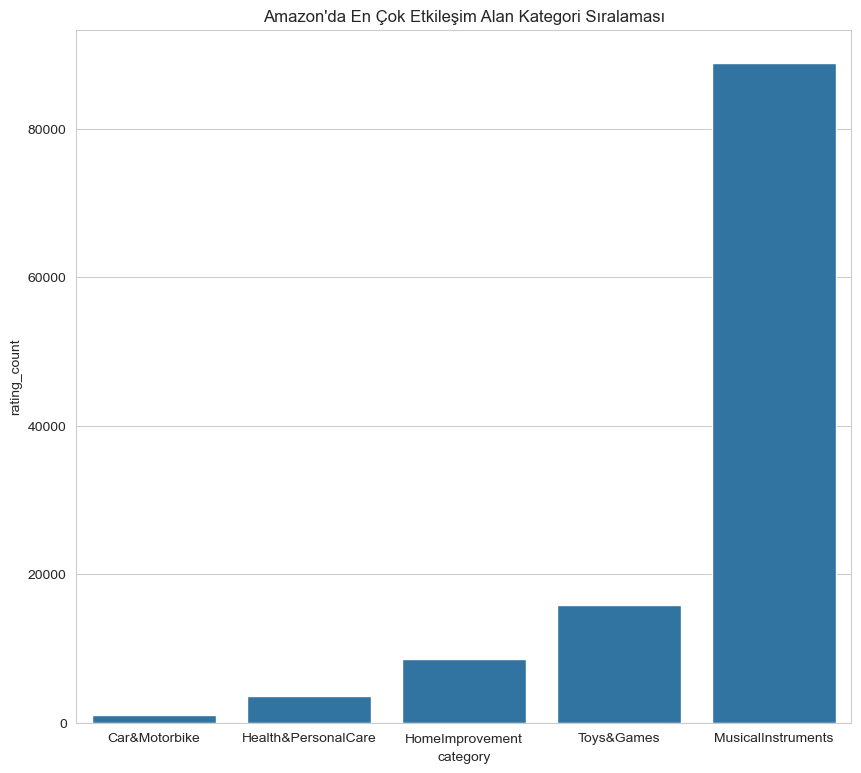

In [42]:
plt.figure(figsize=(10,9))
sns.set_style("whitegrid")
sns.barplot(top_rated_categories)
plt.title("Amazon'da En Çok Etkileşim Alan Kategori Sıralaması")

In [43]:
avg_discount_per_category = df_amazon.groupby("category")["calculated_discount_percentage"].mean().sort_values(ascending=False).head(10)

/var/folders/n_/dfd008j95f371z7x751pd1200000gn/T/ipykernel_10710/3206350271.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=avg_discount_per_category.values, y=avg_discount_per_category.index, palette="magma")


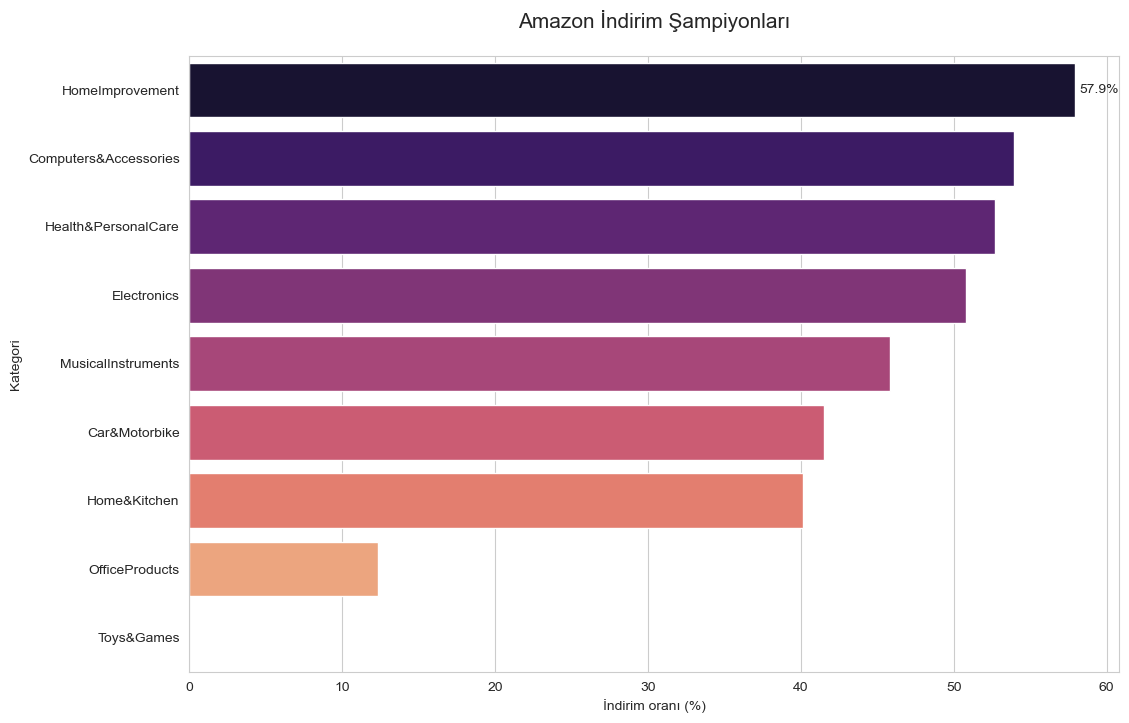

In [56]:
plt.figure(figsize=(12,8))
sns.set_style("whitegrid")
ax = sns.barplot(x=avg_discount_per_category.values, y=avg_discount_per_category.index, palette="magma")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("Amazon İndirim Şampiyonları", fontsize = 15, pad=20)
plt.xlabel("İndirim oranı (%)")
plt.ylabel("Kategori")
plt.savefig('indirim_sampiyonlari', dpi = 300, bbox_inches="tight")
plt.show()

## Temizleme ve Analiz Sonucu (Insights)
1. **İndirim Liderleri:** En yüksek indirim oranları "Home Improvement" ve "Pet Supplies" kategorilerinde görülmektedir.
2. **Fiyat vs Rating:** Ürün fiyatı ile müşteri puanı arasında güçlü bir korelasyon saptanmamıştır; bu da pahalı ürünlerin her zaman daha iyi puan almadığını göstermektedir.
3. **Veri Kalitesi:** Veri setindeki kirli değerler (semboller, yanlış tipler) başarıyla temizlenmiş ve analize uygun hale getirilmiştir.